# 01 · Preprocessing — Caron 2020 Acute Lymphoblastic Leukemia (malignant compartment)

Isolate malignant lymphoblasts, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, and read **Gate 1**
(sample-mixing + manifold continuity) off the regenerated embedding plus a per-neighbourhood metric
(iLISI) across an integration-strength sweep — never a scalar alone.

Caron 2020 is pediatric ALL profiled by 10x across **8 malignant samples spanning three genetically
distinct subtypes** — ETV6-RUNX1 pre-B ALL (4 patients), high-hyperdiploid (HHD) pre-B ALL (2), and
pre-T ALL (2). Each subtype carries its own driver lesion and CNV background, so raw patient/subtype
segregation is expected and **strong Harmony integration is required**; the Gate-1 risk here is that
the three subtypes fail to fuse into one continuous manifold. The blasts are a proliferating
population, so the dominant within-manifold axis is the **cell cycle** — established here and carried
as a declared caveat into 02-04. Every tunable choice is *derived from this dataset*, not inherited
from the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Caron2020_Hematologic-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
# input folder = dataset name minus the '-2' re-analysis suffix
raw_name = 'Data_' + name.replace('-2','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Caron2020_Hematologic-2 | category: Hematologic | raw: Data_Caron2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total + `log1p`, and keeps
the publication `cell_type == 'Malignant'` blasts (dropping normal bone marrow: PBMMC samples). The
publication subtype lives in `obs['source']` and is mapped to a readable label.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
smap = {'Pre-B_ALL':'B-ALL (ETV6-RUNX1)', 'Pre-B_High_hyper_diploid_ALL':'B-ALL (HHD)', 'Pre-T_ALL':'T-ALL'}
adata.obs['subtype'] = adata.obs['source'].map(smap).astype('category')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

full atlas: (37320, 33694)
cell types: {'Malignant': 25788, 'Erythrocyte': 1555, 'T_cell': 1204, 'Macrophage': 447, 'B_cell': 423, 'NK_cell': 152, 'Neutrophil': 106, 'Plasma': 89, 'Monocyte': 68}
malignant: (25788, 33694) | samples: 8
subtypes: {'B-ALL (ETV6-RUNX1)': 13017, 'B-ALL (HHD)': 7926, 'T-ALL': 4845}
expression: X max 7.17 (log1p of normalize_total counts)


### Sample thresholding (data-driven gap-finding)
Sort per-sample malignant counts and test for a dominant multiplicative spillover cliff. Caron's
counts fall smoothly (largest ratio 1.52, top/second 1.16 -> no dominant cliff), so the floor >=100
rule applies and **all 8 malignant samples are retained** (min 1,585 cells).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]; FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'{"dominant cliff -> geometric-mean" if dominant else "no dominant cliff -> floor"} threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'ETV6.RUNX1.2': np.int64(5816), 'HHD.2': np.int64(4780), 'HHD.1': np.int64(3146), 'ETV6.RUNX1.4': np.int64(3022), 'PRE-T.1': np.int64(2866), 'ETV6.RUNX1.1': np.int64(2594), 'PRE-T.2': np.int64(1979), 'ETV6.RUNX1.3': np.int64(1585)}
argmax gap 4780->3146 (ratio 1.52); top/second = 1.16; dominant cliff = False
no dominant cliff -> floor threshold = 100
kept 8/8 samples (min per-sample = 1585) -> 25788 cells


### Overdispersion, PCA, Harmony integration (strength swept)
ALL's three subtypes carry distinct driver lesions/CNVs, so raw PCs are near-perfectly
patient-private (pre-Harmony same-sample neighbour fraction ~1.0). Sweep Harmony `theta`: mixing
plateaus at theta 10-15 (frac ~0.26), and theta=20 over-shrinks and *regresses* mixing (0.40), so
**theta=10** is selected (strong integration without collapse).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50, random_state=SEED)
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:40])
sweep = {}
for th in [5, 10, 15, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:40])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(strong integration; mixing plateaus 10-15, theta=20 regresses)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1332 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1332
same-sample neighbour fraction | pre-Harmony 0.999 | sweep {5: 0.258, 10: 0.256, 15: 0.255, 20: 0.398}
selected theta = 10 (strong integration; mixing plateaus 10-15, theta=20 regresses)


### Embed across an n_pcs sweep + remove detached islands
The kNN graph is a **single connected component at n_pcs = 20, 30 and 40** (robust across the
powered PC range - not under-powered). Embed at n_pcs=30, then strip detached specks with a UMAP
radius graph (6x median NN distance, keep the largest component).

In [6]:
for npc in [20, 30, 40]:
    sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    nc,_ = connected_components(adata.obsp['connectivities'], directed=False)
    print(f'n_pcs={npc}: kNN connected components = {nc}')
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached specks')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

n_pcs=20: kNN connected components = 1
n_pcs=30: kNN connected components = 1
n_pcs=40: kNN connected components = 1
removed 4 cells in 3 detached specks
after island removal: 25784 cells


### Settle manifold biology — cell cycle
Score the Regev-Tirosh S / G2M programmes. A low-resolution Leiden splits the manifold into a
**cycling** pole (cc ~0.24) and a **quiescent** body (cc ~ -0.03), but both lobes carry all three
subtypes in the same proportions - so this is a within-clone proliferation axis, **not** a lineage
split. The whole manifold is kept; the cell-cycle axis is carried as a declared caveat.

In [7]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, [g for g in s_genes if g in adata.var_names],
                             [g for g in g2m_genes if g in adata.var_names])
adata.obs['cc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cc_score per lobe:', adata.obs.groupby('lobe', observed=True)['cc_score'].mean().round(3).to_dict())
print('subtype x lobe:'); print(pd.crosstab(adata.obs['lobe'], adata.obs['subtype']))
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)
print('overall cc_score mean %.3f -> single manifold (cycling+quiescent poles), whole manifold kept' % adata.obs['cc_score'].mean())

lobe sizes: {'1': 18949, '0': 6835}
cc_score per lobe: {'0': 0.235, '1': -0.032}
subtype x lobe:
subtype  B-ALL (ETV6-RUNX1)  B-ALL (HHD)  T-ALL
lobe                                           
0                      3348         2064   1423
1                      9666         5861   3422
overall cc_score mean 0.039 -> single manifold (cycling+quiescent poles), whole manifold kept


### Score developmental modules + house orientation
Score Gast / pSom / Crest against the shared **union** control pool (`score_genes`), graph-smooth
for geography (kNN-averaged, 3 passes), and derive the house **linear layout**: PCA-align the UMAP
and orient the (Gast+pSom-high, Crest-low) developmental origin to the left. Modules correlate only
weakly with the cell cycle (|r| <= 0.12) - the developmental gradients are not a proliferation
artifact.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('global module means (honest raw readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('module vs cell-cycle (raw) Pearson:',
      {l: round(float(np.corrcoef(adata.obs[l], adata.obs['cc_score'])[0,1]),2) for l in ['Gast','pSom','Crest']})
print('smoothed module geography:')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

Gast: 66/81 genes present
pSom: 77/98 genes present
Crest: 93/104 genes present
global module means (honest raw readout): {'Gast': -0.0166, 'pSom': 0.0003, 'Crest': -0.0104}
module vs cell-cycle (raw) Pearson: {'Gast': -0.1, 'pSom': 0.1, 'Crest': -0.12}
smoothed module geography:
  Gast_sm vs pSom_sm: r = -0.46
  Gast_sm vs Crest_sm: r = -0.20
  pSom_sm vs Crest_sm: r = -0.74


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
Per-neighbourhood mixing (iLISI, k=90) rises sharply after Harmony for both `sample` and `subtype`,
the kNN graph is one connected component, and the three genetically distinct subtypes intermix
rather than forming separate lineage islands. **Gate 1 = GO.**

In [9]:
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nb_s = adata.obs['sample'].nunique()
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:30], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:30], adata.obs['sample'].values))
il_sub  = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:30], adata.obs['subtype'].values))
ncomp_knn,_ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'iLISI median sample: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {nb_s} samples')
print(f'iLISI median subtype (post): {il_sub:.2f} of 3 subtypes')
print(f'kNN graph connected components: {ncomp_knn} (=1 -> one continuous manifold)')
print('Gate 1: 3 genetically distinct subtypes intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median sample: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.21 of 8 samples
iLISI median subtype (post): 2.45 of 3 subtypes
kNN graph connected components: 1 (=1 -> one continuous manifold)
Gate 1: 3 genetically distinct subtypes intermix per-neighbourhood on one continuous manifold -> GO


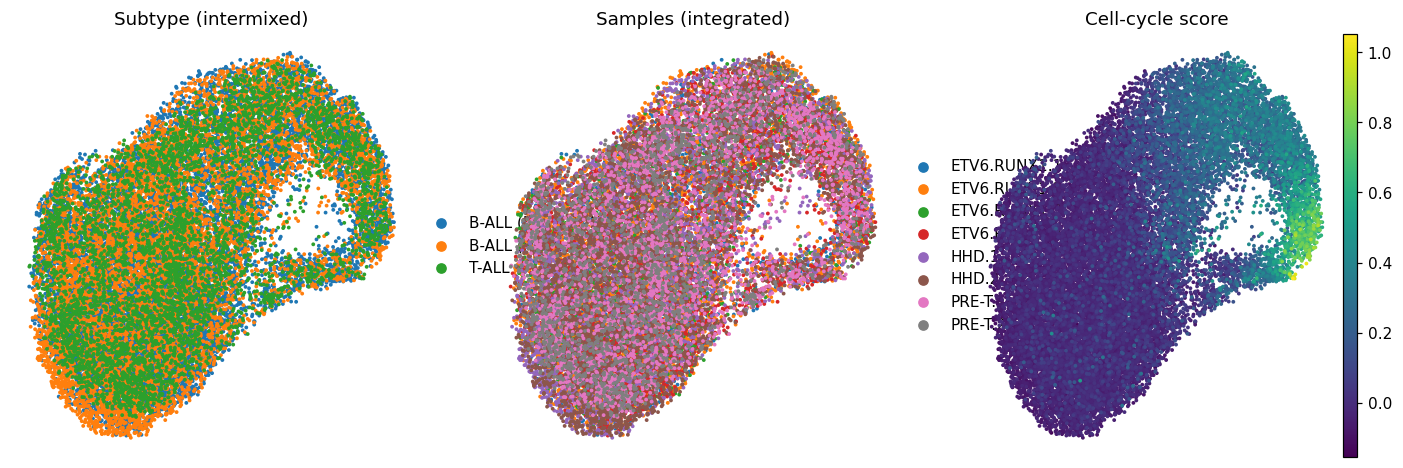

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16,5))
sc.pl.umap(adata, color='subtype', size=25, frameon=False, show=False, ax=ax[0], title='Subtype (intermixed)')
sc.pl.umap(adata, color='sample', size=25, frameon=False, show=False, ax=ax[1], title='Samples (integrated)')
sc.pl.umap(adata, color='cc_score', cmap='viridis', size=25, frameon=False, show=False, ax=ax[2], title='Cell-cycle score')
plt.show()

### Save processed data

In [11]:
protect = {'sample','subtype','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','phase'}
for cix in adata.obs.columns:
    if cix in protect:
        adata.obs[cix] = adata.obs[cix].astype(str).astype('category'); continue
    col = adata.obs[cix]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cix] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (25784, 21935)


### Sample-integration figure (deliverable)
House style - `figsize=(3.5,1.5)` horizontal strip on the linear layout, `size=30`, sample-coloured,
consistent orientation (developmental origin at left).

saved samples.pdf | cells: 25784


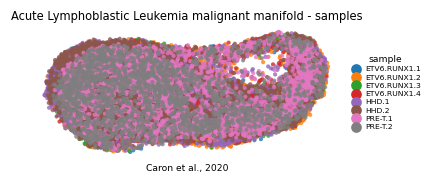

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Acute Lymphoblastic Leukemia malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])